In [2]:
import pandas as pd

df = pd.read_csv("csgo_players.csv")

df.head()

,player_id,nickname,real_name,age,country,current_team,teams,total_kills,total_deaths,headshot_percentage,...,3_kill_rounds,4_kill_rounds,5_kill_rounds,rifle_kills,sniper_kills,smg_kills,pistol_kills,grenade_kills,other_kills,rating
0,11893,ZywOo,Mathieu Herbaut,21,France,Vitality,"Vitality, aAa",22622,16458,41.2%,...,1474,369,71,8261,8552,1290,4262,260,49,1.32
1,7998,s1mple,Aleksandr Kostyliev,24,Ukraine,Natus Vincere,Natus Vincere,35512,26413,41.3%,...,2262,504,64,14717,13451,901,6057,199,254,1.25
2,16920,sh1ro,Dmitry Sokolov,21,Russia,Cloud9,"Gambit Youngsters, Gambit",18091,12492,27.8%,...,1075,221,30,3791,10580,550,3008,175,70,1.26
3,20113,deko,Denis Zhukov,21,Russia,1WIN,1WIN,8738,6397,36.7%,...,518,112,8,2664,4348,181,1459,86,40,1.23
4,18835,saffee,Rafael Costa,27,Brazil,FURIA,"FURIA, paiN",8482,6517,30.9%,...,524,114,14,2545,4412,264,1209,52,28,1.22


In [4]:
print("Total players:", df.shape[0])
print("Total columns:", df.shape[1])

Total players: 811
Total columns: 41


In [5]:
# Check missing values in every column
df.isnull().sum().sort_values(ascending=False)

current_team                         297
player_id                              0
nickname                               0
age                                    0
real_name                              0
country                                0
teams                                  0
total_kills                            0
total_deaths                           0
headshot_percentage                    0
damage_per_round                       0
grenade_dmg_per_round                  0
maps_played                            0
rounds_played                          0
kills_per_death                        0
kills_per_round                        0
assists_per_round                      0
deaths_per_round                       0
saved_by_teammate_per_round            0
saved_teammates_per_round              0
rounds_with_kills                      0
kill_to_death_diff                     0
total_opening_kills                    0
total_opening_deaths                   0
opening_kill_rat

In [6]:
# Replace missing team names with Unknown
df["current_team"] = df["current_team"].fillna("Unknown")

# Check if any missing values remain
print("Missing team values:", df["current_team"].isnull().sum())

# Count players with unknown teams
print("Unknown teams:", (df["current_team"] == "Unknown").sum())

Missing team values: 0
Unknown teams: 297


In [7]:

# Calculate the difference between kills and deaths
df["kill_to_death_diff"] = (
    df["total_kills"] - df["total_deaths"]
)

# Display the first five players
df[[
    "nickname",
    "total_kills",
    "total_deaths",
    "kill_to_death_diff"
]].head()


,nickname,total_kills,total_deaths,kill_to_death_diff
0,ZywOo,22622,16458,6164
1,s1mple,35512,26413,9099
2,sh1ro,18091,12492,5599
3,deko,8738,6397,2341
4,saffee,8482,6517,1965


In [8]:
df[[
    "nickname",
    "kills_per_death",
    "kill_to_death_diff"
]].head(10)

,nickname,kills_per_death,kill_to_death_diff
0,ZywOo,1.37,6164
1,s1mple,1.34,9099
2,sh1ro,1.45,5599
3,deko,1.37,2341
4,saffee,1.30,1965
5,Kaze,1.32,4291
6,degster,1.31,3363
7,smooya,1.26,3849
8,sterling,1.30,3960
9,XANTARES,1.20,6256


In [9]:
df["headshot_percentage"].head(10)

0    41.2%
1    41.3%
2    27.8%
3    36.7%
4    30.9%
5    30.3%
6    34.7%
7    27.8%
8    31.6%
9    53.3%
Name: headshot_percentage, dtype: str

In [10]:
df["headshot_percentage"] = pd.to_numeric(
    df["headshot_percentage"].astype(str).str.replace("%", "", regex=False),
    errors="coerce"
)

df[["nickname", "headshot_percentage"]].head(10)

,nickname,headshot_percentage
0,ZywOo,41.2
1,s1mple,41.3
2,sh1ro,27.8
3,deko,36.7
4,saffee,30.9
5,Kaze,30.3
6,degster,34.7
7,smooya,27.8
8,sterling,31.6
9,XANTARES,53.3


In [11]:
print("Data type:", df["headshot_percentage"].dtype)
print("Invalid values:", df["headshot_percentage"].isna().sum())

Data type: float64
Invalid values: 0


In [12]:
# Display the data type of every column
print(df.dtypes.to_string())

player_id                              int64
nickname                                 str
real_name                                str
age                                    int64
country                                  str
current_team                             str
teams                                    str
total_kills                            int64
total_deaths                           int64
headshot_percentage                  float64
damage_per_round                     float64
grenade_dmg_per_round                float64
maps_played                            int64
rounds_played                          int64
kills_per_death                      float64
kills_per_round                      float64
assists_per_round                    float64
deaths_per_round                     float64
saved_by_teammate_per_round          float64
saved_teammates_per_round            float64
rounds_with_kills                      int64
kill_to_death_diff                     int64
total_open

In [13]:
# Count completely duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check for duplicate player IDs
print("Duplicate player IDs:", df["player_id"].duplicated().sum())

# Check the total records
print("Total players:", len(df))

Duplicate rows: 0
Duplicate player IDs: 0
Total players: 811


In [14]:
# Save the cleaned dataset as a new CSV file
df.to_csv("csgo_players_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Total players:", len(df))
print("Total columns:", len(df.columns))

Cleaned dataset saved successfully!
Total players: 811
Total columns: 41


In [15]:
# Find the 10 highest-rated CS:GO players
top_players = df.sort_values(
    by="rating",
    ascending=False
).head(10)

# Display their statistics
top_players[[
    "nickname",
    "country",
    "rating",
    "kills_per_death",
    "maps_played"
]]

,nickname,country,rating,kills_per_death,maps_played
0,ZywOo,France,1.32,1.37,1020
2,sh1ro,Russia,1.26,1.45,884
1,s1mple,Ukraine,1.25,1.34,1571
3,deko,Russia,1.23,1.37,404
15,blameF,Denmark,1.22,1.26,884
4,saffee,Brazil,1.22,1.30,404
6,degster,Russia,1.21,1.31,686
10,SENSEi,Ukraine,1.21,1.34,474
22,Texta,Australia,1.21,1.16,625
34,chelleos,New Zealand,1.20,1.15,560


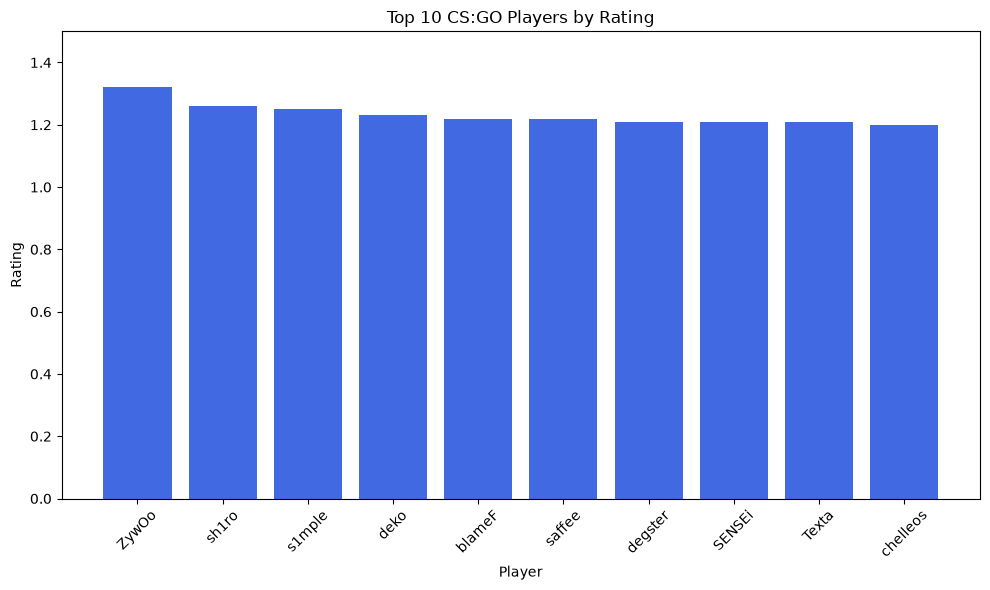

In [16]:

import matplotlib.pyplot as plt

# Create our first chart
plt.figure(figsize=(10, 6))

plt.bar(
    top_players["nickname"],
    top_players["rating"],
    color="royalblue"
)

plt.title("Top 10 CS:GO Players by Rating")
plt.xlabel("Player")
plt.ylabel("Rating")

plt.xticks(rotation=45)
plt.ylim(0, 1.5)

plt.tight_layout()
plt.show()


country
United States    82
Denmark          73
Russia           67
Brazil           61
Sweden           53
Poland           50
Australia        44
China            28
France           26
Finland          26
Name: count, dtype: int64


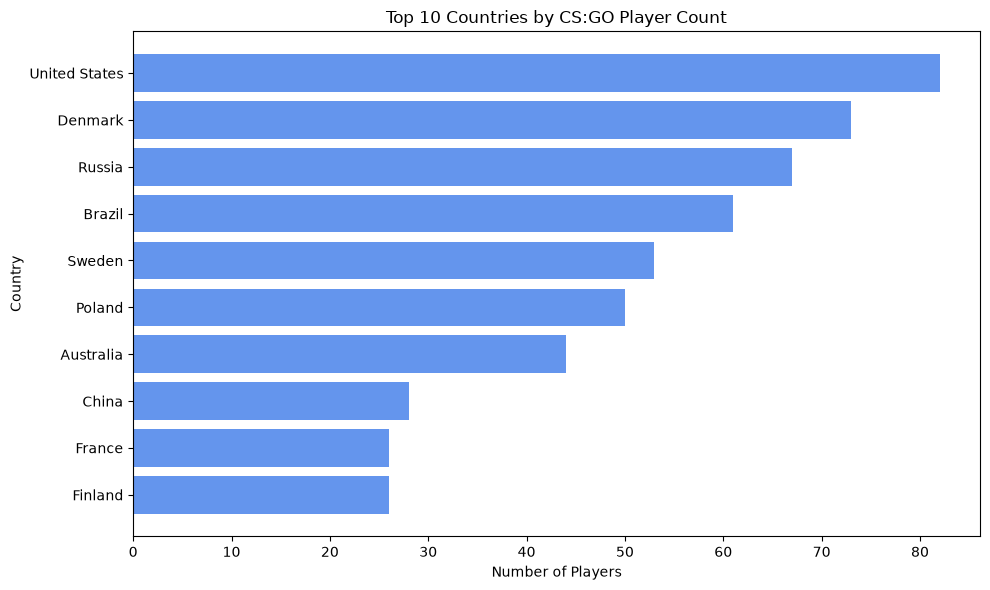

In [17]:

# Count players from each country
country_counts = df["country"].value_counts().head(10)

# Display the results
print(country_counts)

# Create a horizontal bar chart
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    country_counts.index,
    country_counts.values,
    color="cornflowerblue"
)

plt.title("Top 10 Countries by CS:GO Player Count")
plt.xlabel("Number of Players")
plt.ylabel("Country")

# Put the country with the most players at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


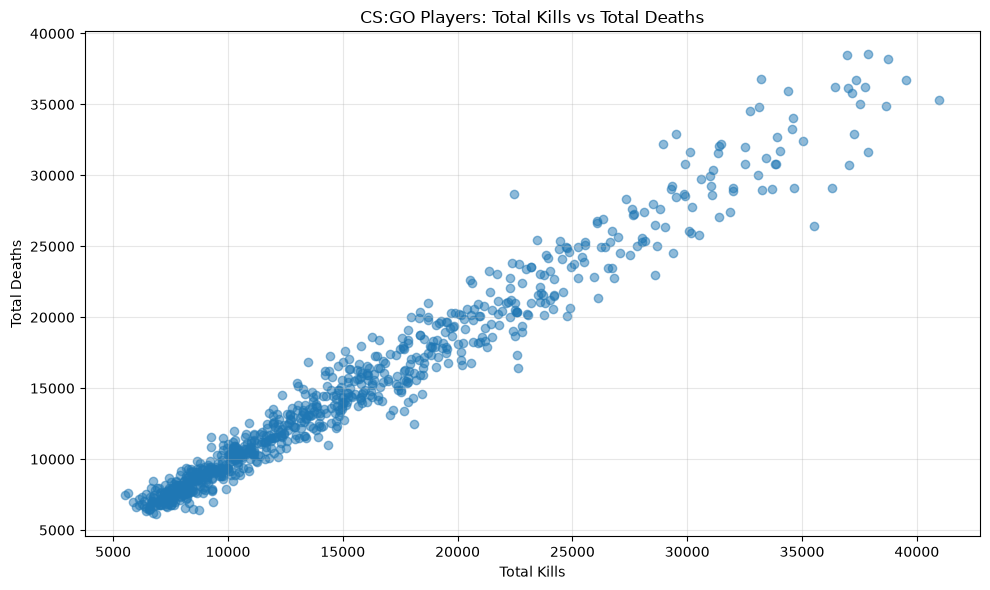

In [18]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df["total_kills"],
    df["total_deaths"],
    alpha=0.5
)

plt.title("CS:GO Players: Total Kills vs Total Deaths")
plt.xlabel("Total Kills")
plt.ylabel("Total Deaths")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:

import plotly.express as px

fig = px.scatter(
    df,
    x="total_kills",
    y="total_deaths",
    hover_name="nickname",
    hover_data=[
        "country",
        "rating",
        "kills_per_death",
        "maps_played"
    ],
    title="CS:GO Player Performance: Kills vs Deaths"
)

fig.update_layout(
    xaxis_title="Total Kills",
    yaxis_title="Total Deaths"
)

fig.show()


In [20]:
print("Total Players:", len(df))
print("Countries Represented:", df["country"].nunique())
print("Average Player Age:", round(df["age"].mean(), 1))
print("Average Player Rating:", round(df["rating"].mean(), 2))
print("Average K/D Ratio:", round(df["kills_per_death"].mean(), 2))

Total Players: 811
Countries Represented: 53
Average Player Age: 25.9
Average Player Rating: 1.03
Average K/D Ratio: 1.04
